# Lab 1: Phân tích và Xử lý Tín hiệu Âm thanh Số
**Môn học:** CSE457 - Xử lý âm thanh và tiếng nói


## Chuẩn bị
Import các thư viện cần thiết và tạo các thư mục kết quả.


In [2]:
!pip install soundfile

   ---------------------------------------- 0.0/1.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.0 MB ? eta -:--:--
   -------------------------------


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import os
import numpy as np
import scipy.signal as signal
import scipy.io.wavfile as wav
import matplotlib.pyplot as plt
import soundfile as sf
import warnings
warnings.filterwarnings('ignore')

# Tạo thư mục nếu chưa có
os.makedirs('audio', exist_ok=True)
os.makedirs('figures', exist_ok=True)


## A. Đọc và kiểm tra dữ liệu âm thanh
Đọc file `input.wav` (được copy từ `audioLab1.wav`). In ra `Fs`, `channels`, `duration`.
Chuẩn hóa về `[-1, 1]` nếu cần.


In [4]:
import shutil
# Copy file âm thanh gốc vào thư mục audio (giả sử script đặt cùng cấp với audioLab1.wav hoặc sinh viên tự copy)
input_file = '../audioLab1.wav'
if os.path.exists(input_file):
    shutil.copy(input_file, 'audio/input.wav')

# Đọc file wav
filename = 'audio/input.wav'
try:
    data, fs = sf.read(filename)
    # Lấy thông tin
    channels = 1 if len(data.shape) == 1 else data.shape[1]
    duration = len(data) / fs
    print(f"File: {filename}")
    print(f"Sample Rate (Fs): {fs} Hz")
    print(f"Channels: {channels}")
    print(f"Duration: {duration:.3f} s")
    
    # Nếu là stereo, chuyển về mono
    if channels == 2:
        print("Chuyển stereo thành mono...")
        data_mono = np.mean(data, axis=1)
    else:
        data_mono = data
        
    # Chuẩn hóa về [-1, 1]
    peak = np.max(np.abs(data_mono))
    if peak > 1.0:
        data_mono = data_mono / peak
    elif peak > 0:
        # Tùy chọn chuẩn hóa
        pass
        
    print(f"Đã chuẩn hóa, Peak hiện tại: {np.max(np.abs(data_mono)):.4f}")
    
except Exception as e:
    print("Lỗi đọc file:", e)
    # Tạo tín hiệu mẫu nếu không có file để code có thể chạy được
    fs = 44100
    t = np.linspace(0, 3, 3*fs, endpoint=False)
    data_mono = 0.5 * np.sin(2*np.pi*440*t) + 0.3 * np.sin(2*np.pi*1000*t)


File: audio/input.wav
Sample Rate (Fs): 44100 Hz
Channels: 2
Duration: 11.052 s
Chuyển stereo thành mono...
Đã chuẩn hóa, Peak hiện tại: 0.3760


## B. Phân tích miền thời gian
Vẽ waveform toàn tệp và 1 đoạn ngắn (0.5 - 1.0s). Tính Peak, RMS.


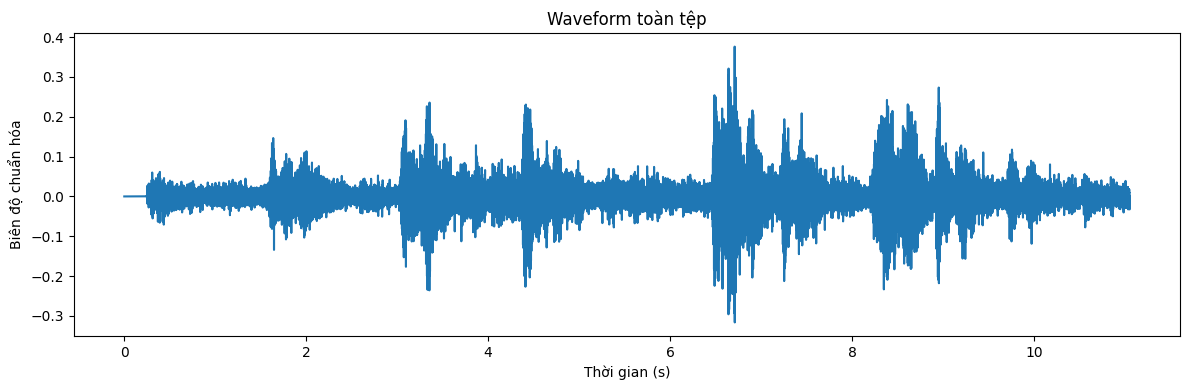

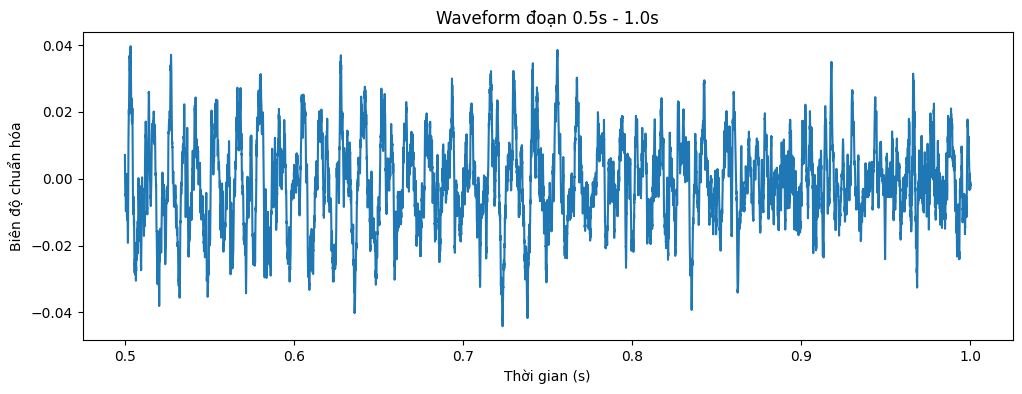

Đoạn 0.5s - 1.0s:
Peak: 0.0441
RMS: 0.0130
Năng lượng: 3.7470


In [5]:
t_total = np.linspace(0, len(data_mono)/fs, len(data_mono), endpoint=False)

plt.figure(figsize=(12, 4))
plt.plot(t_total, data_mono)
plt.title("Waveform toàn tệp")
plt.xlabel("Thời gian (s)")
plt.ylabel("Biên độ chuẩn hóa")
plt.tight_layout()
plt.savefig('figures/waveform.png')
plt.show()

# Đoạn ngắn 0.5 - 1.0s
start_idx = int(0.5 * fs)
end_idx = int(1.0 * fs)
if end_idx <= len(data_mono):
    segment = data_mono[start_idx:end_idx]
    t_seg = t_total[start_idx:end_idx]
    
    plt.figure(figsize=(12, 4))
    plt.plot(t_seg, segment)
    plt.title("Waveform đoạn 0.5s - 1.0s")
    plt.xlabel("Thời gian (s)")
    plt.ylabel("Biên độ chuẩn hóa")
    plt.show()
    
    # Tính Peak và RMS
    peak_val = np.max(np.abs(segment))
    rms_val = np.sqrt(np.mean(segment**2))
    energy_val = np.sum(segment**2)
    print(f"Đoạn 0.5s - 1.0s:")
    print(f"Peak: {peak_val:.4f}")
    print(f"RMS: {rms_val:.4f}")
    print(f"Năng lượng: {energy_val:.4f}")
    if peak_val >= 1.0:
         print("Có nguy cơ clipping!")


**Nhận xét:** Waveform cho thấy cấu trúc thay đổi theo thời gian của âm thanh. Đoạn 0.5-1.0s giúp quan sát rõ hơn các chu kỳ.


## C. Phân tích miền tần số bằng FFT
Tính FFT trên đoạn 0.5 - 1.0s, nhân cửa sổ Hamming.


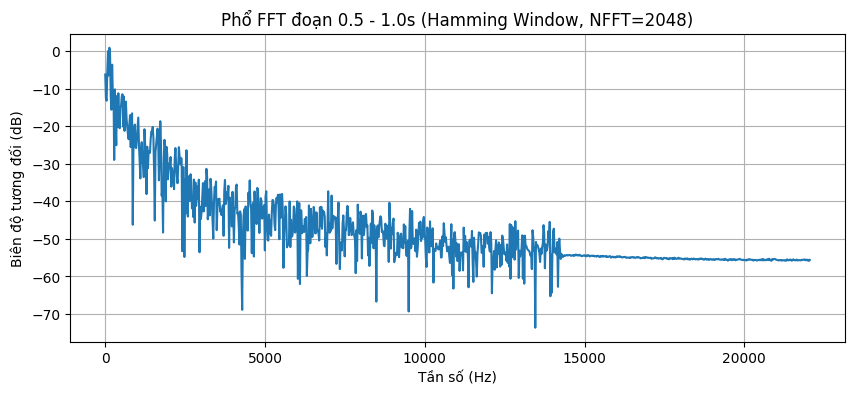

Frequency-bin spacing (Δf) = 21.53 Hz


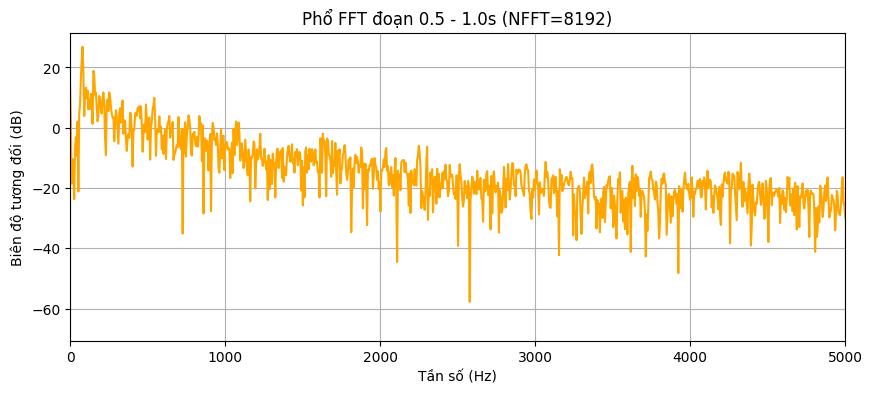

Frequency-bin spacing với NFFT lớn (Δf) = 5.38 Hz


In [6]:
if end_idx <= len(data_mono):
    w = np.hamming(len(segment))
    NFFT = 2048
    X = np.fft.rfft(segment * w, n=NFFT)
    f = np.fft.rfftfreq(NFFT, 1/fs)
    mag_db = 20 * np.log10(np.maximum(np.abs(X), 1e-12))
    
    plt.figure(figsize=(10, 4))
    plt.plot(f, mag_db)
    plt.title("Phổ FFT đoạn 0.5 - 1.0s (Hamming Window, NFFT=2048)")
    plt.xlabel("Tần số (Hz)")
    plt.ylabel("Biên độ tương đối (dB)")
    plt.grid(True)
    plt.savefig('figures/fft.png')
    plt.show()
    
    print(f"Frequency-bin spacing (Δf) = {fs/NFFT:.2f} Hz")
    
    # Thử với NFFT = 8192
    NFFT_large = 8192
    X_large = np.fft.rfft(segment * w, n=NFFT_large)
    f_large = np.fft.rfftfreq(NFFT_large, 1/fs)
    mag_db_large = 20 * np.log10(np.maximum(np.abs(X_large), 1e-12))
    
    plt.figure(figsize=(10, 4))
    plt.plot(f_large, mag_db_large, color='orange')
    plt.title("Phổ FFT đoạn 0.5 - 1.0s (NFFT=8192)")
    plt.xlabel("Tần số (Hz)")
    plt.ylabel("Biên độ tương đối (dB)")
    plt.xlim(0, 5000) # Phóng to vùng 0-5kHz
    plt.grid(True)
    plt.show()
    
    print(f"Frequency-bin spacing với NFFT lớn (Δf) = {fs/NFFT_large:.2f} Hz")


**Nhận xét:** Việc tăng `NFFT` làm giảm `Δf` (tăng mật độ điểm trên trục tần số) nhưng không làm tăng true frequency resolution vì resolution thật sự phụ thuộc vào chiều dài frame (số lượng mẫu thực tế).


## D. STFT và Spectrogram


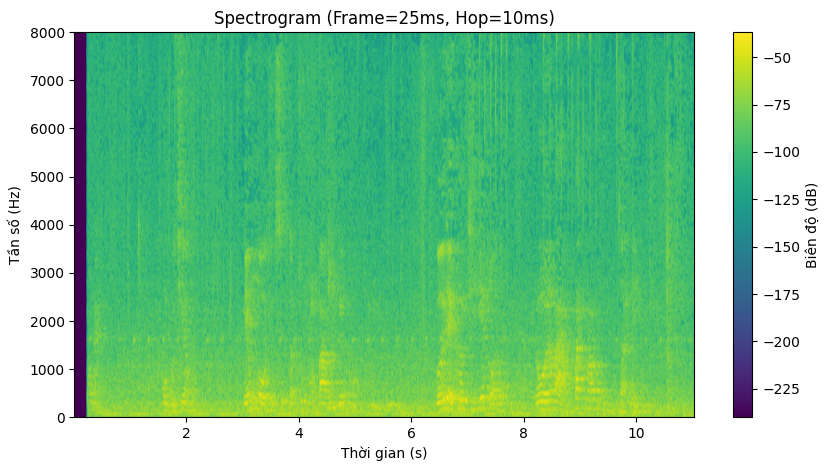

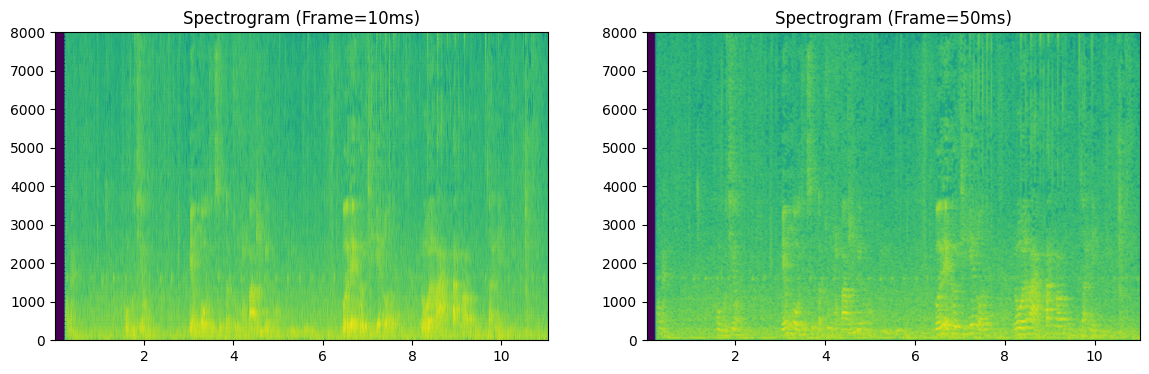

In [7]:
L = int(0.025 * fs) # Frame length ~ 25ms
H = int(0.010 * fs) # Hop size ~ 10ms

# Tính STFT
f_stft, t_stft, S = signal.spectrogram(
    data_mono, fs=fs, window='hamming',
    nperseg=L, noverlap=L-H, nfft=2048, mode='magnitude'
)

S_db = 20 * np.log10(np.maximum(S, 1e-12))

plt.figure(figsize=(10, 5))
plt.pcolormesh(t_stft, f_stft, S_db, shading='gouraud', cmap='viridis')
plt.title("Spectrogram (Frame=25ms, Hop=10ms)")
plt.ylabel("Tần số (Hz)")
plt.xlabel("Thời gian (s)")
plt.colorbar(label="Biên độ (dB)")
plt.ylim(0, 8000) # Giới hạn xem đến 8kHz
plt.savefig('figures/spectrogram.png')
plt.show()

# Thử với frame = 10ms và 50ms
L10 = int(0.010 * fs)
f1, t1, S1 = signal.spectrogram(data_mono, fs=fs, window='hamming', nperseg=L10, noverlap=L10//2, mode='magnitude')

L50 = int(0.050 * fs)
f2, t2, S2 = signal.spectrogram(data_mono, fs=fs, window='hamming', nperseg=L50, noverlap=L50//2, mode='magnitude')

fig, axs = plt.subplots(1, 2, figsize=(14, 4))
axs[0].pcolormesh(t1, f1, 20*np.log10(np.maximum(S1, 1e-12)), shading='gouraud')
axs[0].set_title("Spectrogram (Frame=10ms)")
axs[0].set_ylim(0, 8000)

axs[1].pcolormesh(t2, f2, 20*np.log10(np.maximum(S2, 1e-12)), shading='gouraud')
axs[1].set_title("Spectrogram (Frame=50ms)")
axs[1].set_ylim(0, 8000)
plt.show()


**Nhận xét:** Frame ngắn (10ms) cho độ phân giải thời gian tốt (time resolution) nhưng độ phân giải tần số kém (các đường ngang bị mờ). Frame dài (50ms) cho độ phân giải tần số tốt nhưng độ phân giải thời gian bị giảm.


## E. Thí nghiệm cửa sổ
So sánh Rectangular và Hamming.


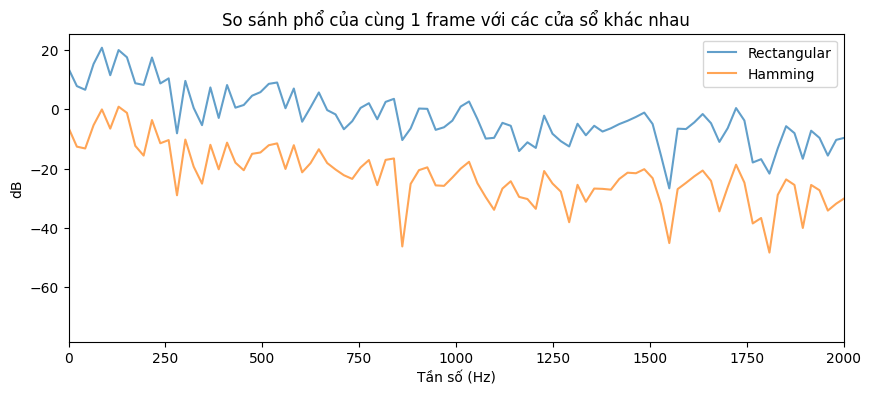

In [8]:
if end_idx <= len(data_mono):
    w_rect = np.ones(len(segment))
    w_hamm = np.hamming(len(segment))
    
    X_rect = np.fft.rfft(segment * w_rect, n=2048)
    X_hamm = np.fft.rfft(segment * w_hamm, n=2048)
    
    db_rect = 20 * np.log10(np.maximum(np.abs(X_rect), 1e-12))
    db_hamm = 20 * np.log10(np.maximum(np.abs(X_hamm), 1e-12))
    f_win = np.fft.rfftfreq(2048, 1/fs)
    
    plt.figure(figsize=(10, 4))
    plt.plot(f_win, db_rect, label='Rectangular', alpha=0.7)
    plt.plot(f_win, db_hamm, label='Hamming', alpha=0.7)
    plt.title("So sánh phổ của cùng 1 frame với các cửa sổ khác nhau")
    plt.xlabel("Tần số (Hz)")
    plt.ylabel("dB")
    plt.xlim(0, 2000)
    plt.legend()
    plt.show()


**Nhận xét:** Cửa sổ Rectangular có main-lobe hẹp hơn nhưng side-lobe cao, gây ra hiện tượng spectral leakage nghiêm trọng. Cửa sổ Hamming làm giảm spectral leakage nhưng làm main-lobe rộng ra một chút.


## F. Lọc số (FIR)
Thiết kế bộ lọc Low-pass và High-pass.


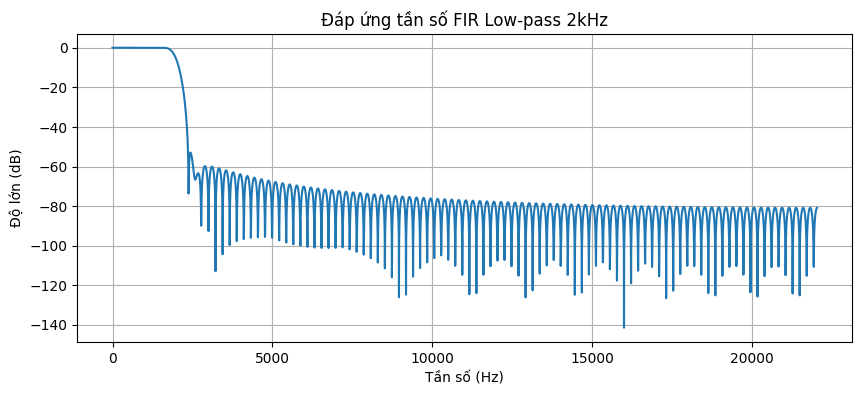

Đã lưu audio/filtered_lowpass.wav
Đã lưu audio/filtered_highpass.wav


In [9]:
# Low-pass 2000 Hz
numtaps = 201
cutoff_lp = 2000
b_lp = signal.firwin(numtaps, cutoff=cutoff_lp, fs=fs, window='hamming')

w_lp, H_lp = signal.freqz(b_lp, worN=4096, fs=fs)

plt.figure(figsize=(10, 4))
plt.plot(w_lp, 20 * np.log10(np.abs(H_lp)))
plt.title("Đáp ứng tần số FIR Low-pass 2kHz")
plt.xlabel("Tần số (Hz)")
plt.ylabel("Độ lớn (dB)")
plt.grid(True)
plt.savefig('figures/filter_response.png')
plt.show()

# Áp dụng bộ lọc
y_lp = signal.lfilter(b_lp, [1.0], data_mono)
sf.write('audio/filtered_lowpass.wav', y_lp, fs)
print("Đã lưu audio/filtered_lowpass.wav")

# High-pass 2000 Hz
b_hp = signal.firwin(numtaps, cutoff=cutoff_lp, fs=fs, window='hamming', pass_zero=False)
y_hp = signal.lfilter(b_hp, [1.0], data_mono)
sf.write('audio/filtered_highpass.wav', y_hp, fs)
print("Đã lưu audio/filtered_highpass.wav")


## G. Lượng tử hóa, resampling và mã hóa
Lượng tử hóa 4, 8, 16 bit và tính SNR.


In [14]:
def quantize(x, B):
    qmax = 2**(B-1) - 1
    return np.round(np.clip(x, -1, 1)*qmax) / qmax

def snr_db(x, xq):
    e = xq - x
    num = np.sum(x*x)
    den = np.sum(e*e)
    if den == 0:
        return float('inf')
    return 10 * np.log10(num/den)

for B in [4, 8, 16]:
    xq = quantize(data_mono, B)
    snr = snr_db(data_mono, xq)
    print(f"Lượng tử hóa {B} bit - SNR: {snr:.2f} dB")
    sf.write(f'audio/quantized_{B}bit.wav', xq, fs)

# Resampling
try:
    import librosa
    fs_new = 16000
    y_16k = librosa.resample(data_mono, orig_sr=fs, target_sr=fs_new)
    sf.write('audio/resampled_16kHz.wav', y_16k, fs_new)
    print("Đã resample và lưu audio/resampled_16kHz.wav")
except ImportError:
    print("Vui lòng cài đặt librosa để chạy phần resampling: pip install librosa")

# Tính Bit rate lý thuyết cho file 16-bit PCM stereo (hoặc mono) ở 44.1kHz
bit_rate_pcm = fs * 16 * channels
print(f"Bit rate PCM lý thuyết: {bit_rate_pcm} bps ({bit_rate_pcm/1000} kbps)")


Lượng tử hóa 4 bit - SNR: 2.81 dB
Lượng tử hóa 8 bit - SNR: 24.17 dB
Lượng tử hóa 16 bit - SNR: 71.03 dB
Đã resample và lưu audio/resampled_16kHz.wav
Bit rate PCM lý thuyết: 1411200 bps (1411.2 kbps)
